<a href="https://colab.research.google.com/github/AndresAvella09/Proyecto_Multimodal/blob/main/notebooks/10_buscador_evaluacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/AndresAvella09/Proyecto_Multimodal/blob/main/notebooks/10_buscador_evaluacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 10 · Buscador: mejorar la sinopsis y medir qué tan bien busca

En el notebook 09 vimos que buscar **por póster** funciona bien, pero buscar **por sinopsis** con CLIP no:
todas las sinopsis tienen similitud entre 0.77 y 0.93 con cualquier búsqueda, así que el orden es casi al azar.
La razón es que el codificador de texto de CLIP se entrenó para frases cortas que describen imágenes, no para textos largos.

Este notebook hace dos cosas:

1. **Cambia la representación de la sinopsis** por [multilingual-e5-base](https://huggingface.co/intfloat/multilingual-e5-base),
   un modelo entrenado justamente para *buscar documentos largos a partir de una frase corta*, en ~100 idiomas
   (incluye español e inglés) y con textos de hasta 512 tokens (entra la sinopsis completa).
2. **Mide con números** qué tan bien busca cada opción, usando búsquedas cuya respuesta correcta conocemos.

| Sección | Qué hace | Archivo que guarda |
|---|---|---|
| 1 | Carga datos, vectores y modelos | — |
| 2 | Calcula los vectores E5 de las 25 959 sinopsis (**usar GPU**, ~10 min) | `embeddings/e5_txt.npy` |
| 3 | Comparación a ojo: sinopsis con CLIP vs. con E5 | — |
| 4 | Evaluación: precision@10, recall@100 y mAP para cada forma de buscar | `resultados/busqueda_por_consulta.csv` |
| 5 | ¿Cuánto peso darle al póster? (barrido de `alfa`) | `resultados/busqueda_alfa.csv` |
| 6 | Resultados por género y por idioma | — |


In [ ]:
import os, sys, io, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    !pip install -q sentence-transformers

BASE = os.environ.get('PM_BASE', '/content/drive/MyDrive/proyecto_multimodal')
DATA, EMB, RES = f'{BASE}/data', f'{BASE}/embeddings/embeddings', f'{BASE}/resultados'
os.makedirs(RES, exist_ok=True)

pelis = pd.read_parquet(f'{DATA}/mmimdb_con_anio.parquet')       # notebook 05
assert (pelis['fila_hdf5'].values == np.arange(len(pelis))).all()
GENEROS = [c[4:] for c in pelis.columns if c.startswith('hoy_')]
pelis['titulo'] = pelis['titulo'].fillna('(sin título)')
pelis['anio_txt'] = pelis['anio'].astype('Int64').astype(str).replace('<NA>', '?')
ES_CINE = pelis['es_pelicula'].fillna(False).values.astype(bool)

def l2(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True).clip(min=1e-8)

V_POSTER = l2(np.load(f'{EMB}/clip_img.npy').astype(np.float32))      # notebook 03
V_SIN_CLIP = l2(np.load(f'{EMB}/clip_txt.npy').astype(np.float32))    # notebook 03

POSTERS = pd.read_parquet(f'{DATA}/posters_mini.parquet')['jpg'].tolist()   # notebook 07
print(f'{len(pelis):,} películas ({ES_CINE.sum():,} de cine) | {len(GENEROS)} géneros')

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 110})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
25,959 películas (23,547 de cine) | 23 géneros


## 1. Los modelos de texto

| Para qué | Modelo | Espacio |
|---|---|---|
| Búsqueda → **póster** | CLIP multilingüe (igual que en el 09) | el de CLIP (512) |
| Búsqueda → **sinopsis** (antes) | CLIP multilingüe contra los vectores CLIP de la sinopsis | el de CLIP (512) |
| Búsqueda → **sinopsis** (ahora) | **multilingual-e5-base** | uno propio (768) |

E5 pide un prefijo en cada texto: `query: ` para la búsqueda y `passage: ` para el documento (la sinopsis).

In [ ]:
import torch
from sentence_transformers import SentenceTransformer

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', device, '(si dice cpu, la sección 2 va a tardar mucho: activa la GPU)')

modelo_clip = SentenceTransformer('sentence-transformers/clip-ViT-B-32-multilingual-v1', device=device)
modelo_e5 = SentenceTransformer('intfloat/multilingual-e5-base', device=device)
modelo_e5.max_seq_length = 512
if device == 'cuda':
    modelo_e5.half()      # más rápido en la T4, sin cambio apreciable en los vectores

def codificar_clip(textos):
    return l2(modelo_clip.encode(textos, convert_to_numpy=True).astype(np.float32))

def codificar_e5(textos, tipo='query', **kw):
    # tipo: 'query' para búsquedas, 'passage' para sinopsis
    textos = [f'{tipo}: {t}' for t in textos]
    return modelo_e5.encode(textos, convert_to_numpy=True, normalize_embeddings=True, **kw).astype(np.float32)

Dispositivo: cuda (si dice cpu, la sección 2 va a tardar mucho: activa la GPU)


modules.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.65k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/572 [00:00<?, ?B/s]

... (21 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

## 2. Vectores E5 de las sinopsis

Se calculan una sola vez y se guardan en `embeddings/e5_txt.npy` (en el mismo orden que el HDF5).

In [ ]:
RUTA_E5 = f'{EMB}/e5_txt.npy'

if os.path.exists(RUTA_E5):
    V_SIN_E5 = np.load(RUTA_E5)
    print('Cargados de Drive:', V_SIN_E5.shape)
else:
    V_SIN_E5 = codificar_e5(pelis['sinopsis'].fillna('').tolist(), 'passage',
                            batch_size=64, show_progress_bar=True)
    np.save(RUTA_E5, V_SIN_E5)
    print('Guardado', RUTA_E5, V_SIN_E5.shape)

assert len(V_SIN_E5) == len(pelis)

Batches:   0%|          | 0/406 [00:00<?, ?it/s]

Guardado /content/drive/MyDrive/proyecto_multimodal/embeddings/embeddings/e5_txt.npy (25959, 768)


## 3. Comparación a ojo: sinopsis con CLIP vs. con E5

Las mismas búsquedas de trama del notebook 09, ahora con los dos tipos de vectores de sinopsis.

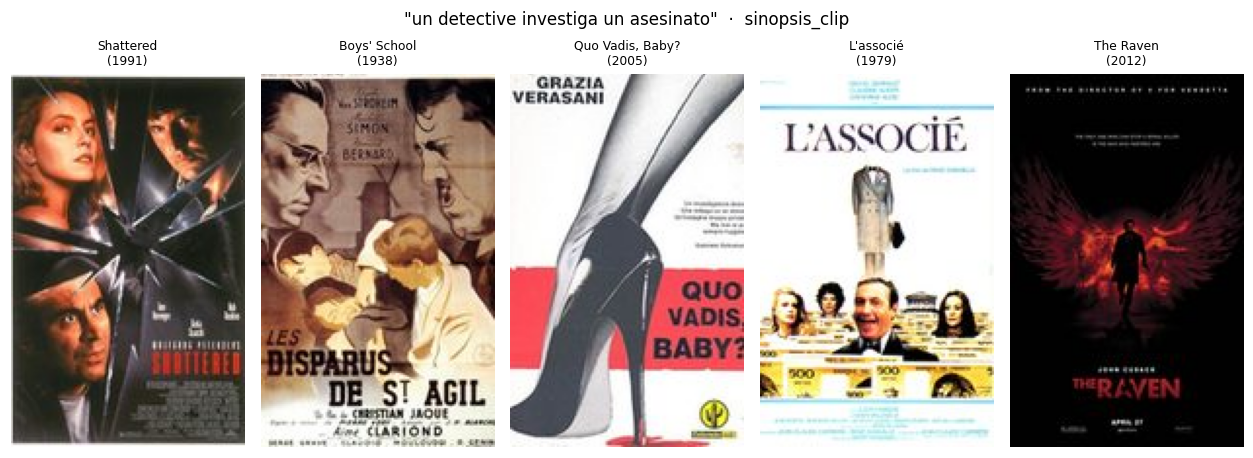

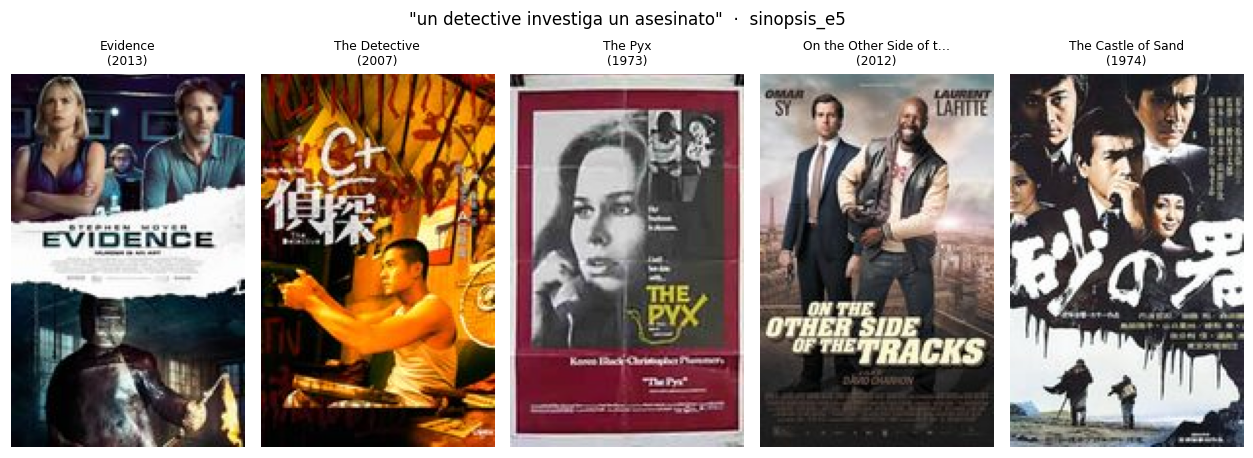

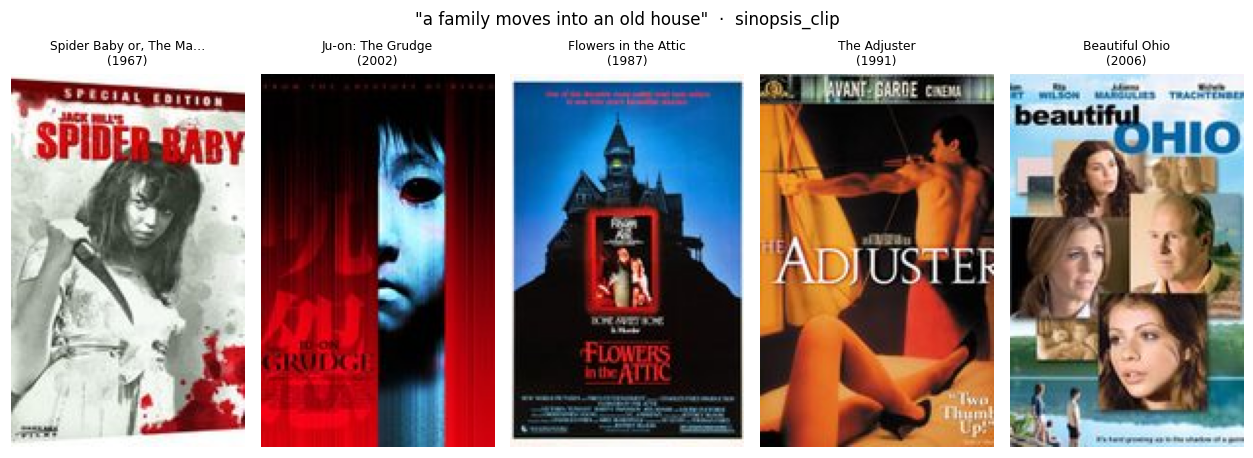

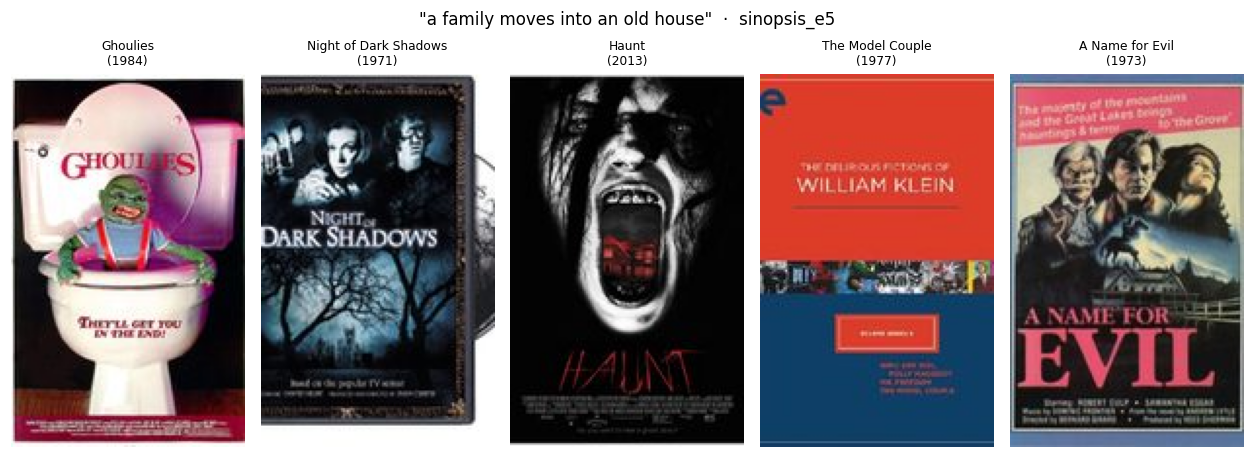

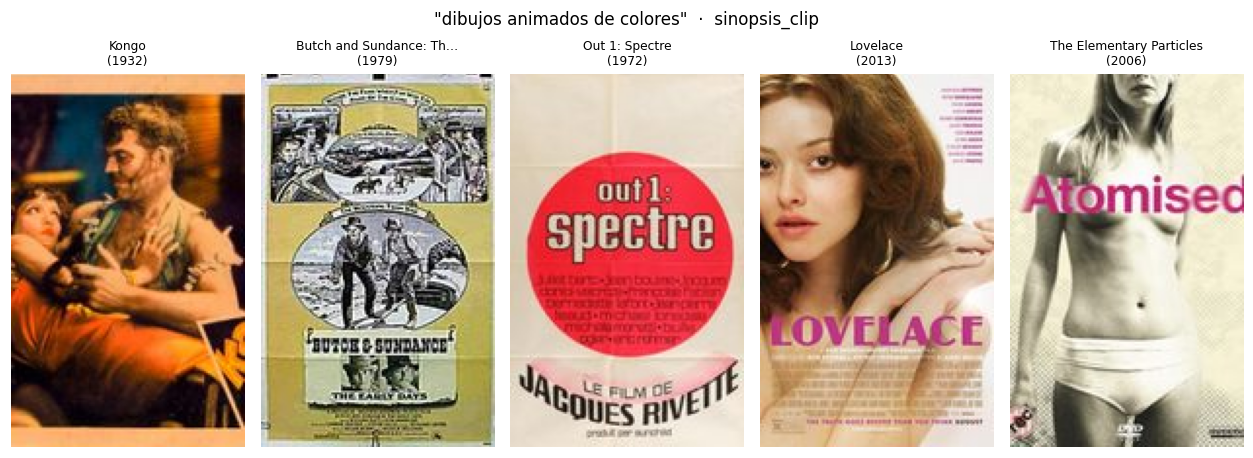

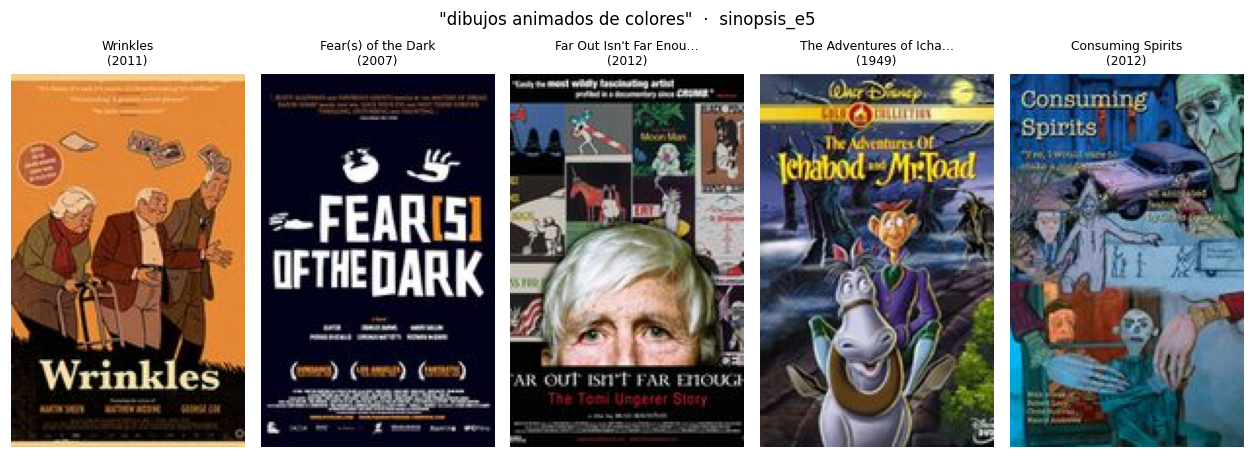

CLIP: similitudes entre 0.23 y 0.91 | distancia del 1.º al 100.º en desviaciones estándar: 0.85
  E5: similitudes entre 0.66 y 0.86 | distancia del 1.º al 100.º en desviaciones estándar: 2.05


In [ ]:
from PIL import Image

def zscore(S):
    # estandariza cada fila (cada búsqueda) sobre el catálogo: pone póster y sinopsis en la misma escala
    return (S - S.mean(axis=-1, keepdims=True)) / (S.std(axis=-1, keepdims=True) + 1e-8)

def puntajes(consultas, modo, alfa=0.5):
    # (n_consultas, n_peliculas) para un modo de búsqueda
    if modo in ('poster', 'sinopsis_clip', 'ambos_clip', 'ambos_e5'):
        qc = codificar_clip(consultas)
    if modo in ('sinopsis_e5', 'ambos_e5'):
        qe = codificar_e5(consultas, 'query')
    if modo == 'poster':        return qc @ V_POSTER.T
    if modo == 'sinopsis_clip': return qc @ V_SIN_CLIP.T
    if modo == 'sinopsis_e5':   return qe @ V_SIN_E5.T
    if modo == 'ambos_clip':    return alfa * zscore(qc @ V_POSTER.T) + (1 - alfa) * zscore(qc @ V_SIN_CLIP.T)
    if modo == 'ambos_e5':      return alfa * zscore(qc @ V_POSTER.T) + (1 - alfa) * zscore(qe @ V_SIN_E5.T)
    raise ValueError(modo)

def buscar(consulta, modo='ambos_e5', k=10, alfa=0.5, solo_cine=True):
    s = puntajes([consulta], modo, alfa)[0]
    if solo_cine:
        s = np.where(ES_CINE, s, -np.inf)
    top = np.argsort(-s)[:k]
    res = pelis.iloc[top][['fila_hdf5', 'titulo', 'anio_txt', 'generos_imdb_hoy']].copy()
    res['puntaje'] = s[top]
    return res.reset_index(drop=True)

def mostrar(res, titulo='', columnas=5):
    filas = int(np.ceil(len(res) / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(2.3 * columnas, 4.4 * filas))
    for ax in np.atleast_1d(axes).flat:
        ax.axis('off')
    for ax, (_, r) in zip(np.atleast_1d(axes).flat, res.iterrows()):
        ax.imshow(Image.open(io.BytesIO(POSTERS[int(r['fila_hdf5'])])))
        nombre = r['titulo'] if len(r['titulo']) <= 24 else r['titulo'][:22] + '…'
        ax.set_title(f"{nombre}\n({r['anio_txt']})", fontsize=8)
    if titulo:
        fig.suptitle(titulo, fontsize=11)
    plt.tight_layout(h_pad=2.0); plt.show()

for c in ['un detective investiga un asesinato', 'a family moves into an old house',
          'dibujos animados de colores']:
    for m in ['sinopsis_clip', 'sinopsis_e5']:
        mostrar(buscar(c, modo=m, k=5), f'"{c}"  ·  {m}')

# ¿Sigue el problema de "todas se parecen igual"?
for nombre, m in [('CLIP', 'sinopsis_clip'), ('E5', 'sinopsis_e5')]:
    s = puntajes(['a family moves into an old house'], m)[0]
    print(f'{nombre:>4}: similitudes entre {s.min():.2f} y {s.max():.2f} | '
          f'distancia del 1.º al 100.º en desviaciones estándar: {(np.sort(s)[-1] - np.sort(s)[-100]) / s.std():.2f}')

## 4. Evaluación con números

**Idea:** usar búsquedas cuya respuesta correcta conocemos. Si alguien busca *"una película de terror"*,
las respuestas correctas son las películas con `hoy_Horror = 1` (etiquetas de IMDb hoy, notebook 05).

Para cada género hay **4 búsquedas**: una frase y una palabra, en español y en inglés.
Solo se buscan películas de cine y solo entran géneros con al menos 50 películas en el catálogo.

**Métricas** (para cada búsqueda, y luego el promedio):

| Métrica | Qué responde |
|---|---|
| **precision@10** | De los 10 primeros resultados, ¿qué fracción es del género? Es lo que el usuario ve. |
| **recall@100** | De todas las películas del género, ¿qué fracción aparece en los 100 primeros? |
| **AP** (*average precision*) y **mAP** (su promedio) | Calidad de **todo** el orden: premia poner las correctas arriba. 1 = perfecto. |
| **azar** | El AP de un orden al azar = proporción de películas del género. Es el piso. |

Los intervalos de confianza (IC 95 %) se calculan con **bootstrap sobre géneros**: se remuestrean los géneros
con reemplazo 2 000 veces. Así el IC refleja que con otro conjunto de géneros el resultado podría cambiar.

**Ojo con la interpretación:** buscar por género favorece a la sinopsis, porque los géneros se deciden sobre todo
por la trama. Es una prueba justa para comparar *las dos versiones de la sinopsis* entre sí, pero no dice que el póster
sea inútil: para búsquedas visuales ("pósters oscuros", "dibujos de colores") no hay etiquetas para medir.

In [ ]:
# (frase en español, palabra en español, frase en inglés, palabra en inglés)
CONSULTAS = {
    'Drama': ('una película dramática', 'drama', 'a drama movie', 'drama'),
    'Comedy': ('una película de comedia', 'comedia', 'a comedy movie', 'comedy'),
    'Romance': ('una película romántica', 'romance', 'a romantic movie', 'romance'),
    'Thriller': ('una película de suspenso', 'suspenso', 'a thriller movie', 'thriller'),
    'Crime': ('una película de crimen', 'crimen', 'a crime movie', 'crime'),
    'Action': ('una película de acción', 'acción', 'an action movie', 'action'),
    'Adventure': ('una película de aventuras', 'aventura', 'an adventure movie', 'adventure'),
    'Horror': ('una película de terror', 'terror', 'a horror movie', 'horror'),
    'Documentary': ('un documental', 'documental', 'a documentary', 'documentary'),
    'Mystery': ('una película de misterio', 'misterio', 'a mystery movie', 'mystery'),
    'Sci-Fi': ('una película de ciencia ficción', 'ciencia ficción', 'a science fiction movie', 'sci-fi'),
    'Fantasy': ('una película de fantasía', 'fantasía', 'a fantasy movie', 'fantasy'),
    'Family': ('una película familiar', 'familia', 'a family movie', 'family'),
    'Biography': ('una película biográfica', 'biografía', 'a biographical movie', 'biography'),
    'War': ('una película de guerra', 'guerra', 'a war movie', 'war'),
    'History': ('una película histórica', 'historia', 'a historical movie', 'history'),
    'Music': ('una película sobre música', 'música', 'a movie about music', 'music'),
    'Animation': ('una película animada', 'animación', 'an animated movie', 'animation'),
    'Musical': ('un musical', 'musical', 'a musical', 'musical'),
    'Western': ('una película del oeste', 'vaqueros', 'a western movie', 'western'),
    'Sport': ('una película de deportes', 'deportes', 'a sports movie', 'sports'),
    'Short': ('un cortometraje', 'corto', 'a short film', 'short'),
    'Film-Noir': ('una película de cine negro', 'cine negro', 'a film noir', 'noir'),
}
TIPOS = [('es', 'frase'), ('es', 'palabra'), ('en', 'frase'), ('en', 'palabra')]

Y_CAT = pelis.loc[ES_CINE, [f'hoy_{g}' for g in GENEROS]].values       # etiquetas del catálogo (solo cine)
n_pos = pd.Series(Y_CAT.sum(axis=0), index=GENEROS)
GEN_EVAL = [g for g in GENEROS if n_pos[g] >= 50 and g in CONSULTAS]
print(f'Géneros evaluados: {len(GEN_EVAL)} | fuera (menos de 50 películas): '
      f'{ {g: int(n_pos[g]) for g in GENEROS if g not in GEN_EVAL} }')

consultas = pd.DataFrame([{'genero': g, 'idioma': i, 'tipo': t, 'texto': CONSULTAS[g][k]}
                          for g in GEN_EVAL for k, (i, t) in enumerate(TIPOS)])
print(f'{len(consultas)} búsquedas de evaluación')
consultas.head(8)

Géneros evaluados: 22 | fuera (menos de 50 películas): {'Short': 0}
88 búsquedas de evaluación


,genero,idioma,tipo,texto
0,Drama,es,frase,una película dramática
1,Drama,es,palabra,drama
2,Drama,en,frase,a drama movie
3,Drama,en,palabra,drama
4,Comedy,es,frase,una película de comedia
5,Comedy,es,palabra,comedia
6,Comedy,en,frase,a comedy movie
7,Comedy,en,palabra,comedy


In [ ]:
from sklearn.metrics import average_precision_score

def evaluar(S, consultas):
    # S: (n_consultas, n_catalogo) puntajes -> métricas por consulta
    filas = []
    for i, g in enumerate(consultas['genero']):
        y = Y_CAT[:, GENEROS.index(g)]
        orden = np.argsort(-S[i])
        filas.append({'p@10': y[orden[:10]].mean(),
                      'r@100': y[orden[:100]].sum() / y.sum(),
                      'AP': average_precision_score(y, S[i])})
    return pd.DataFrame(filas)

MODOS = ['poster', 'sinopsis_clip', 'sinopsis_e5', 'ambos_clip', 'ambos_e5']
textos = consultas['texto'].tolist()
S = {m: puntajes(textos, m)[:, ES_CINE] for m in MODOS}

por_consulta = []
for m in MODOS:
    r = pd.concat([consultas.reset_index(drop=True), evaluar(S[m], consultas)], axis=1)
    r['modo'] = m
    por_consulta.append(r)
por_consulta = pd.concat(por_consulta, ignore_index=True)
por_consulta['azar'] = por_consulta['genero'].map(n_pos / ES_CINE.sum())
por_consulta.to_csv(f'{RES}/busqueda_por_consulta.csv', index=False)
print('Guardado resultados/busqueda_por_consulta.csv')

Guardado resultados/busqueda_por_consulta.csv


In [ ]:
rng = np.random.default_rng(42)
B = 2000

def ic_bootstrap_generos(df, col):
    # media e IC 95 % remuestreando géneros (cada género = promedio de sus 4 búsquedas)
    x = df.groupby('genero')[col].mean().values
    medias = rng.choice(x, size=(B, len(x)), replace=True).mean(axis=1)
    return x.mean(), *np.percentile(medias, [2.5, 97.5])

tabla = []
for m in MODOS:
    d = por_consulta[por_consulta['modo'] == m]
    fila = {'modo': m}
    for col in ['p@10', 'r@100', 'AP']:
        media, lo, hi = ic_bootstrap_generos(d, col)
        fila[col] = f'{media:.3f} [{lo:.3f}, {hi:.3f}]'
    tabla.append(fila)
tabla = pd.DataFrame(tabla).rename(columns={'AP': 'mAP'})
print(f"Piso (azar), mAP: {por_consulta.groupby('genero')['azar'].first().mean():.3f}\n")
tabla

Piso (azar), mAP: 0.107



,modo,p@10,r@100,mAP
0,poster,"0.436 [0.326, 0.545]","0.026 [0.016, 0.038]","0.204 [0.144, 0.272]"
1,sinopsis_clip,"0.168 [0.091, 0.253]","0.008 [0.007, 0.011]","0.121 [0.070, 0.182]"
2,sinopsis_e5,"0.549 [0.444, 0.651]","0.029 [0.020, 0.040]","0.222 [0.161, 0.286]"
3,ambos_clip,"0.419 [0.316, 0.528]","0.023 [0.015, 0.034]","0.188 [0.126, 0.259]"
4,ambos_e5,"0.545 [0.427, 0.658]","0.036 [0.024, 0.049]","0.263 [0.203, 0.328]"


In [ ]:
# ¿E5 mejora a CLIP en la sinopsis? Diferencia PAREADA por género (mismas búsquedas, mismo género)
def dif_pareada(m1, m2, col='AP'):
    a = por_consulta[por_consulta.modo == m1].groupby('genero')[col].mean()
    b = por_consulta[por_consulta.modo == m2].groupby('genero')[col].mean()
    d = (a - b).values
    medias = rng.choice(d, size=(B, len(d)), replace=True).mean(axis=1)
    lo, hi = np.percentile(medias, [2.5, 97.5])
    print(f'{m1:>13} − {m2:<13}: {d.mean():+.3f}  IC 95 % [{lo:+.3f}, {hi:+.3f}]  '
          f'| gana en {(d > 0).sum()}/{len(d)} géneros')

dif_pareada('sinopsis_e5', 'sinopsis_clip')
dif_pareada('ambos_e5', 'ambos_clip')
dif_pareada('ambos_e5', 'sinopsis_e5')
dif_pareada('ambos_e5', 'poster')

  sinopsis_e5 − sinopsis_clip: +0.101  IC 95 % [+0.066, +0.145]  | gana en 20/22 géneros
     ambos_e5 − ambos_clip   : +0.075  IC 95 % [+0.046, +0.109]  | gana en 19/22 géneros
     ambos_e5 − sinopsis_e5  : +0.041  IC 95 % [+0.015, +0.066]  | gana en 18/22 géneros
     ambos_e5 − poster       : +0.060  IC 95 % [+0.030, +0.091]  | gana en 19/22 géneros


## 5. ¿Cuánto peso darle al póster?

En el modo `ambos`, `alfa` es el peso del póster: `alfa = 0` es solo sinopsis y `alfa = 1` es solo póster.
Si la mejor mezcla está en un punto intermedio, **las dos modalidades aportan**. Si está en un extremo,
una de las dos sobra. Es la misma pregunta del proyecto (¿se aprovechan las dos fuentes?) aplicada a la búsqueda.

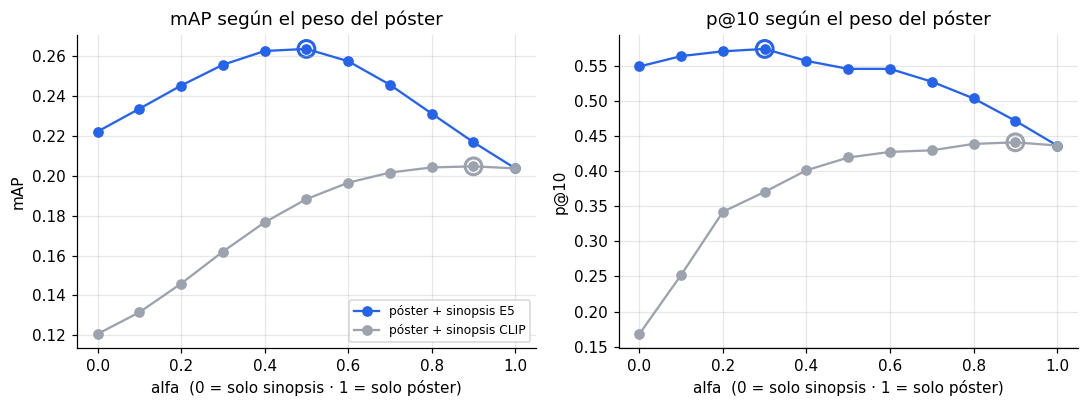

Sinopsis E5: mejor alfa = 0.5 (mAP 0.263) | solo sinopsis 0.222 | solo póster 0.204
Sinopsis CLIP: mejor alfa = 0.9 (mAP 0.205) | solo sinopsis 0.121 | solo póster 0.204


In [ ]:
ALFAS = np.round(np.arange(0, 1.01, 0.1), 1)
qc, qe = codificar_clip(textos), codificar_e5(textos, 'query')
Zp = zscore(qc @ V_POSTER.T)[:, ES_CINE]
Zs = {'clip': zscore(qc @ V_SIN_CLIP.T)[:, ES_CINE], 'e5': zscore(qe @ V_SIN_E5.T)[:, ES_CINE]}

filas = []
for sin, Zsin in Zs.items():
    for a in ALFAS:
        r = evaluar(a * Zp + (1 - a) * Zsin, consultas)
        r['genero'] = consultas['genero'].values
        m_ap = r.groupby('genero')['AP'].mean().mean()
        m_p10 = r.groupby('genero')['p@10'].mean().mean()
        filas.append({'sinopsis': sin, 'alfa': a, 'mAP': m_ap, 'p@10': m_p10})
barrido = pd.DataFrame(filas)
barrido.to_csv(f'{RES}/busqueda_alfa.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col in zip(axes, ['mAP', 'p@10']):
    for sin, color in [('e5', '#2563eb'), ('clip', '#9ca3af')]:
        d = barrido[barrido.sinopsis == sin]
        ax.plot(d['alfa'], d[col], marker='o', color=color, label=f'póster + sinopsis {sin.upper()}')
        mejor = d.loc[d[col].idxmax()]
        ax.scatter([mejor['alfa']], [mejor[col]], s=120, facecolors='none', edgecolors=color, lw=2)
    ax.set_xlabel('alfa  (0 = solo sinopsis · 1 = solo póster)'); ax.set_ylabel(col)
    ax.set_title(f'{col} según el peso del póster')
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

for sin in ['e5', 'clip']:
    d = barrido[barrido.sinopsis == sin]
    mejor = d.loc[d['mAP'].idxmax()]
    print(f"Sinopsis {sin.upper()}: mejor alfa = {mejor['alfa']:.1f} (mAP {mejor['mAP']:.3f}) | "
          f"solo sinopsis {d.iloc[0]['mAP']:.3f} | solo póster {d.iloc[-1]['mAP']:.3f}")

## 6. Resultados por género y por idioma

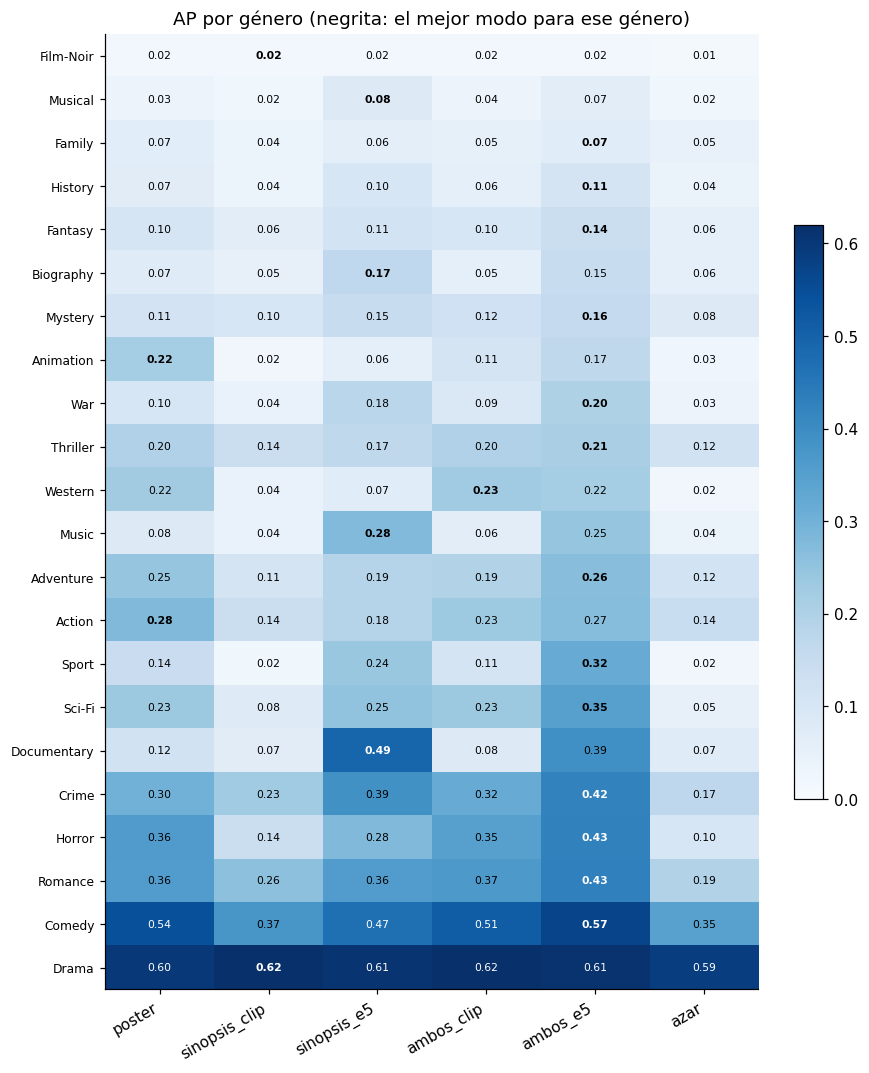

Géneros donde el póster solo le gana a la sinopsis E5: ['Family', 'Animation', 'Thriller', 'Western', 'Adventure', 'Action', 'Horror', 'Comedy']


In [ ]:
ap_gen = (por_consulta.groupby(['genero', 'modo'])['AP'].mean().unstack()[MODOS])
ap_gen['azar'] = n_pos[ap_gen.index] / ES_CINE.sum()
ap_gen = ap_gen.sort_values('ambos_e5')

fig, ax = plt.subplots(figsize=(8, 0.38 * len(ap_gen) + 1.5))
im = ax.imshow(ap_gen.values, cmap='Blues', aspect='auto', vmin=0, vmax=max(0.6, ap_gen.values.max()))
ax.set_xticks(range(ap_gen.shape[1]), ap_gen.columns, rotation=30, ha='right')
ax.set_yticks(range(len(ap_gen)), ap_gen.index, fontsize=8)
for i in range(ap_gen.shape[0]):
    fila = ap_gen.values[i, :len(MODOS)]
    for j in range(ap_gen.shape[1]):
        v = ap_gen.values[i, j]
        negrita = j < len(MODOS) and v == fila.max()
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7,
                fontweight='bold' if negrita else 'normal',
                color='white' if v > 0.4 else 'black')
ax.set_title('AP por género (negrita: el mejor modo para ese género)')
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.show()

gana_poster = ap_gen.index[ap_gen['poster'] > ap_gen['sinopsis_e5']].tolist()
print('Géneros donde el póster solo le gana a la sinopsis E5:', gana_poster or 'ninguno')

In [ ]:
# ¿Busca igual de bien en español que en inglés? ¿Y con frase o con una sola palabra?
for col in ['idioma', 'tipo']:
    t = (por_consulta.groupby(['modo', col])['AP'].mean().unstack()
         .loc[MODOS].round(3))
    print(f'mAP por {col}:'); print(t.to_string()); print()

mAP por idioma:
idioma            en     es
modo                       
poster         0.220  0.187
sinopsis_clip  0.123  0.119
sinopsis_e5    0.232  0.212
ambos_clip     0.202  0.174
ambos_e5       0.283  0.244

mAP por tipo:
tipo           frase  palabra
modo                         
poster         0.215    0.192
sinopsis_clip  0.121    0.120
sinopsis_e5    0.216    0.228
ambos_clip     0.195    0.182
ambos_e5       0.268    0.259



## Resumen y siguiente paso

**Archivos nuevos:**
- `embeddings/e5_txt.npy`: vectores E5 de las sinopsis (768 números por película).
- `resultados/busqueda_por_consulta.csv` y `resultados/busqueda_alfa.csv`: todas las métricas.

**Qué mirar en los resultados:**
1. ¿E5 mejora la búsqueda por sinopsis frente a CLIP? (sección 4, diferencia pareada con su IC)
2. ¿El mejor `alfa` está en el medio? Si sí, póster y sinopsis aportan cosas distintas (sección 5).
3. ¿En qué géneros gana el póster? (sección 6; en el notebook 04 el póster ganaba en Animation, Family y Musical)
4. ¿El español busca igual de bien que el inglés?

**Paso 3:** entrenar una capa pequeña encima de los vectores para que la búsqueda entienda mejor los géneros
(representación inicial → entrenamiento → representación final), y comparar con estas mismas métricas.